In [1580]:
#Install packages
import pandas as pd
import numpy as np
import math

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm   # only for the Q-Q plot in the helper below

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.impute import SimpleImputer, KNNImputer

pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',None)

In [1581]:
#Define Functions
def diagnostic_plots(y_true, y_pred):
    """The four residual plots from lecture, side by side."""
    resid = y_true - y_pred

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    axes[0].scatter(y_pred, resid, alpha=0.6)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Fitted values')
    axes[0].set_ylabel('Residuals')
    axes[0].set_title('Residuals vs. Fitted')

    axes[1].scatter(y_pred, y_true, alpha=0.6)
    lims = [min(y_pred.min(), y_true.min()), max(y_pred.max(), y_true.max())]
    axes[1].plot(lims, lims, color='red', linestyle='--')
    axes[1].set_xlabel('Fitted values')
    axes[1].set_ylabel('Actual values')
    axes[1].set_title('Actual vs. Fitted')

    sm.qqplot(resid, line='s', ax=axes[2])
    axes[2].set_title('Normal Q-Q')

    axes[3].hist(resid, bins=20, edgecolor='white')
    axes[3].axvline(0, color='red', linestyle='--')
    axes[3].set_xlabel('Residual')
    axes[3].set_title('Histogram of Residuals')

    plt.tight_layout()
    plt.show()


#AI assisted haversine formula "as the crow flies" distance between two lat/long coordinates in km
# Vectorized with numpy so it works on whole DataFrame columns (NaN in -> NaN out) as well as scalars
def haversine(lat1, lon1, lat2, lon2, unit="km"):
    # Earth's radius in kilometers or miles
    R = 6371.0 if unit == "km" else 3958.8

    # Convert decimal degrees to radians
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    dphi = np.radians(lat2 - lat1)
    dlambda = np.radians(lon2 - lon1)

    # Haversine formula
    a = (
        np.sin(dphi / 2) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(dlambda / 2) ** 2
    )
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return R * c


In [1582]:
#Read and split data
df = pd.read_csv('Taxi-cancellation-case.csv',index_col=0)

X = df.drop(columns=['Car_Cancellation'])
y = df['Car_Cancellation']

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    stratify=y,
    random_state=42
)

y_train_cancellation_rate = y_train.sum()/len(y_train)
y_test_cancellation_rate = y_test.sum()/len(y_test)
print(y_train_cancellation_rate)
print(y_test_cancellation_rate)

X_train.shape

0.07425
0.0745


(8000, 17)

#### Question 1: Split data and benchmark cancellation rate
We split the data into a 80/20 train/test split using stratified sampling to ensure there was a representative number of cancellations in both our train and test set. We confirmed this by taking total cancellations divided by observations for both the train and test set. A cancellation rate of 7.4% for both datasets gives us comfort there was no unintentional drift.

---

In [1583]:
#Assess Missingness
missingness_rate = (X_train.isna().sum() / len(X_train))
print(missingness_rate.sort_values(ascending=False))

to_city_id             0.966875
package_id             0.826375
from_city_id           0.627625
to_date                0.418250
to_long                0.206750
to_lat                 0.206750
to_area_id             0.206750
from_area_id           0.001625
from_long              0.001625
from_lat               0.001625
booking_created        0.000000
user_id                0.000000
mobile_site_booking    0.000000
online_booking         0.000000
vehicle_model_id       0.000000
travel_type_id         0.000000
from_date              0.000000
dtype: float64


In [1584]:
#Analytics on the travel type id

print(X_train['travel_type_id'].value_counts())

null_travel_types = X_train.drop(columns='travel_type_id').isna().groupby(X_train['travel_type_id']).sum()
print(null_travel_types)

travel_type_id
2    6346
3    1389
1     265
Name: count, dtype: int64
                user_id  vehicle_model_id  package_id  from_area_id  \
travel_type_id                                                        
1                     0                 0         265            13   
2                     0                 0        6346             0   
3                     0                 0           0             0   

                to_area_id  from_city_id  to_city_id  from_date  to_date  \
travel_type_id                                                             
1                      265            40           0          0       12   
2                        0          3668        6346          0     2828   
3                     1389          1313        1389          0      506   

                online_booking  mobile_site_booking  booking_created  \
travel_type_id                                                         
1                            0                  

#### Question 2: Assess Missingness
travel type has an imapct on null values. The first observarion is only category 3 (hourly rentals) tend to use a package id. Additionally it seems most hourly rentals or long distance do not populate a destination area/city/lat/long. Interestingly it seems most point-to-point bookings only populate an area or lat/long or area data, leaving city id null. It seems the city identification is primarily used for long distance trips as this is the only location variable populated for this grouping.

| Structural Missingness| Real Gap |
|-----------------------|-----------|
|package_id|from_lat|
|to_area_id|from_long|
|to_city_id|to_date|
|to_lat|from_city_id|
|to_long|from_area_id|

---

In [1585]:
y = X_train['to_date'].isna().astype(int)

X = pd.DataFrame({
    'online_booking': X_train['online_booking'],
    'mobile_site_booking': X_train['mobile_site_booking'],
    'to_lat_missing': X_train['to_lat'].isna().astype(int),
    'long_distance_1': (X_train['travel_type_id'] == 1).astype(int),
    'point_to_point_2': (X_train['travel_type_id'] == 2).astype(int),
    'hourly_rental_3': (X_train['travel_type_id'] == 3).astype(int),
    'from_city_id_missing': X_train['from_city_id'].isna().astype(int)

})

usable = X.notna().all(axis=1)
X, y = X[usable], y[usable]

print(len(X), "rides,", X.shape[1], "features")

8000 rides, 7 features


In [1586]:
X_train_slice, X_test_slice, y_train_slice, y_test_slice = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train_slice.shape, X_test_slice.shape)

(6400, 7) (1600, 7)


In [1587]:
# Majority-class basline (score to beat)

print("Share of rides missing to date:", round(y_train_slice.mean(), 3))
print("Majority-class baseline:            ", round(1 - y_train_slice.mean(), 3))

Share of rides missing to date: 0.418
Majority-class baseline:             0.582


In [1588]:
# K-fold cross validation
# KNN Classifier: 11

folds = KFold(n_splits=10, shuffle=True, random_state=42)

for k in [1, 3, 5, 7, 11, 15, 21, 31]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(pipe, X_train_slice, y_train_slice, cv=folds, scoring='accuracy')
    print("k =", k, " CV accuracy:", round(scores.mean(), 3))

k = 1  CV accuracy: 0.747
k = 3  CV accuracy: 0.835
k = 5  CV accuracy: 0.84
k = 7  CV accuracy: 0.841
k = 11  CV accuracy: 0.84
k = 15  CV accuracy: 0.841
k = 21  CV accuracy: 0.841
k = 31  CV accuracy: 0.841


In [1589]:
# Pipeline creation

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11))
knn.fit(X_train_slice, y_train_slice)

pred = knn.predict(X_test_slice)

In [1590]:
print(confusion_matrix(y_test_slice, pred))

[[678 253]
 [ 19 650]]


In [1591]:
print("Baseline (predict 'present' always):", round(1 - y_test_slice.mean(), 3))
print()
print("Accuracy: ", round(accuracy_score(y_test_slice, pred), 3))
print("Precision:", round(precision_score(y_test_slice, pred), 3))
print("Recall:   ", round(recall_score(y_test_slice, pred), 3))

Baseline (predict 'present' always): 0.582

Accuracy:  0.83
Precision: 0.72
Recall:    0.972


### Question 3: Test for MCAR
The classifier beats the baseline (.83 > .582), whether a ride has a to_date or not
is predictable from whether or not from_city_id is missing or not.
to_date is not missing completly at random.

---

In [1592]:
X_train.head(10)

,user_id,vehicle_model_id,package_id,travel_type_id,from_area_id,to_area_id,from_city_id,to_city_id,from_date,to_date,online_booking,mobile_site_booking,booking_created,from_lat,from_long,to_lat,to_long
row#,,,,,,,,,,,,,,,,,
9818,39476,12,NaN,2,1237.0,393.0,15.0,NaN,8/15/2013 3:50,8/15/2013 5:03,0,0,8/14/2013 17:37,12.926450,77.612060,13.199560,77.706880
8710,41644,12,1.0,3,1026.0,NaN,15.0,NaN,11/5/2013 7:40,11/5/2013 10:20,0,0,10/31/2013 9:37,13.104820,77.576310,NaN,NaN
1405,25651,12,NaN,1,392.0,NaN,15.0,41.0,3/8/2013 6:28,3/8/2013 0:00,0,0,3/7/2013 13:42,12.986284,77.735245,NaN,NaN
4779,33804,54,NaN,1,571.0,NaN,1.0,32.0,7/13/2013 6:57,7/13/2013 0:00,1,0,7/8/2013 14:09,12.951850,77.696420,NaN,NaN
7861,30869,12,1.0,3,1017.0,NaN,NaN,NaN,10/5/2013 8:24,10/5/2013 13:52,0,0,10/4/2013 11:01,13.110840,77.600740,NaN,NaN
5948,2961,12,NaN,1,182.0,NaN,15.0,32.0,8/12/2013 10:04,8/12/2013 23:59,1,0,8/11/2013 18:29,12.945740,77.649280,NaN,NaN
1706,23109,12,NaN,2,393.0,1254.0,NaN,NaN,3/24/2013 18:14,3/25/2013 0:00,1,0,3/24/2013 9:26,13.199560,77.706880,12.934048,77.580568
106,21727,85,NaN,2,393.0,793.0,NaN,NaN,1/6/2013 21:36,NaN,0,0,1/6/2013 12:07,13.199560,77.706880,13.022390,77.594920
5114,33243,12,NaN,2,1395.0,363.0,NaN,NaN,7/19/2013 6:57,7/19/2013 8:15,0,0,7/18/2013 21:24,13.005603,77.628214,12.992870,77.716620


In [1593]:
missingness_rate = (X_train.isna().sum() / len(X_train))
print(missingness_rate.sort_values(ascending=False))

to_city_id             0.966875
package_id             0.826375
from_city_id           0.627625
to_date                0.418250
to_long                0.206750
to_lat                 0.206750
to_area_id             0.206750
from_area_id           0.001625
from_long              0.001625
from_lat               0.001625
booking_created        0.000000
user_id                0.000000
mobile_site_booking    0.000000
online_booking         0.000000
vehicle_model_id       0.000000
travel_type_id         0.000000
from_date              0.000000
dtype: float64


In [1594]:
X_train.columns

Index(['user_id', 'vehicle_model_id', 'package_id', 'travel_type_id',
       'from_area_id', 'to_area_id', 'from_city_id', 'to_city_id', 'from_date',
       'to_date', 'online_booking', 'mobile_site_booking', 'booking_created',
       'from_lat', 'from_long', 'to_lat', 'to_long'],
      dtype='str')

In [1595]:
X_train.dtypes

user_id                  int64
vehicle_model_id         int64
package_id             float64
travel_type_id           int64
from_area_id           float64
to_area_id             float64
from_city_id           float64
to_city_id             float64
from_date                  str
to_date                    str
online_booking           int64
mobile_site_booking      int64
booking_created            str
from_lat               float64
from_long              float64
to_lat                 float64
to_long                float64
dtype: object

In [1596]:
X_train.nunique()

user_id                5831
vehicle_model_id         20
package_id                6
travel_type_id            3
from_area_id            495
to_area_id              454
from_city_id              2
to_city_id               61
from_date              6645
to_date                4329
online_booking            2
mobile_site_booking       2
booking_created        7746
from_lat                401
from_long               398
to_lat                  372
to_long                 369
dtype: int64

In [1597]:
X_train['package_id_missing'] = np.where(X_train['package_id'].isna(),1,0)
X_train['to_date_missing'] = np.where(X_train['to_date'].isna(),1,0)
X_train = X_train.drop(columns=['user_id','package_id','to_city_id','from_city_id','to_date'])

drop_rows = X_train[X_train['from_area_id'].isna() | X_train['from_lat'].isna() | X_train['from_long'].isna()].index
X_train = X_train.drop(index=drop_rows)
y_train = y_train.drop(index=drop_rows)

X_train = pd.get_dummies(X_train, columns=['vehicle_model_id','travel_type_id'],drop_first=True,dtype=int)

#Deal with the dates, used AI to help engineer numeric feautres from datetime data
for c in ['from_date', 'booking_created']:
    X_train[c] = pd.to_datetime(X_train[c])

X_train['booking_days_before_trip'] = (X_train['from_date'] - X_train['booking_created']).dt.total_seconds() / 86400
X_train['from_hour']  = X_train['from_date'].dt.hour
X_train['from_dow']   = X_train['from_date'].dt.dayofweek
X_train['from_month'] = X_train['from_date'].dt.month

X_train = X_train.drop(columns=['from_date', 'booking_created'])
X_train = pd.get_dummies(X_train, columns=['from_hour', 'from_dow', 'from_month'], drop_first=True,dtype=int)

X_train['haversine_km'] = haversine(X_train['from_lat'], X_train['from_long'],
                                    X_train['to_lat'],   X_train['to_long'])

X_train.shape

/var/folders/m9/_pg_9rkd0ngdmqrhjmr8pk6c0000gn/T/ipykernel_8634/2121802813.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X_train['from_dow']   = X_train['from_date'].dt.dayofweek


(7987, 71)

In [1598]:
drop_cols = ['to_lat']
features = [c for c in X_train.columns if c not in drop_cols]
X_train_area = X_train[features]

has_area_destination = X_train['to_lat'].notna() & X_train_area[features].notna().all(axis=1)

X_area = X_train.loc[has_area_destination, features]
y_area = X_train.loc[has_area_destination, 'to_lat']

print(len(X_area), "cars have an area destination with every feature present")
print("Lat range: mean", round(y_area.mean()), " std", round(y_area.std()))

6346 cars have an area destination with every feature present
Lat range: mean 13  std 0


In [1599]:
folds = KFold(n_splits=10, shuffle=True, random_state=42)

for k in [10, 30, 50, 70, 110, 150, 210, 310, 510, 1010]:
    pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    scores = cross_val_score(pipe, X_area, y_area, cv=folds,
                             scoring='neg_root_mean_squared_error')
    print("k =", k, " CV RMSE: ", round(-scores.mean(),ndigits=4))

k = 10  CV RMSE:  0.0915
k = 30  CV RMSE:  0.0918
k = 50  CV RMSE:  0.0921
k = 70  CV RMSE:  0.092
k = 110  CV RMSE:  0.0922
k = 150  CV RMSE:  0.0927
k = 210  CV RMSE:  0.0938
k = 310  CV RMSE:  0.0951
k = 510  CV RMSE:  0.0968
k = 1010  CV RMSE:  0.0997


In [1600]:
X_train.dtypes

from_area_id                float64
to_area_id                  float64
online_booking                int64
mobile_site_booking           int64
from_lat                    float64
from_long                   float64
to_lat                      float64
to_long                     float64
package_id_missing            int64
to_date_missing               int64
vehicle_model_id_10           int64
vehicle_model_id_12           int64
vehicle_model_id_17           int64
vehicle_model_id_23           int64
vehicle_model_id_24           int64
vehicle_model_id_28           int64
vehicle_model_id_30           int64
vehicle_model_id_36           int64
vehicle_model_id_54           int64
vehicle_model_id_64           int64
vehicle_model_id_65           int64
vehicle_model_id_85           int64
vehicle_model_id_86           int64
vehicle_model_id_87           int64
vehicle_model_id_89           int64
vehicle_model_id_90           int64
vehicle_model_id_91           int64
travel_type_id_2            

In [1601]:
prep = make_pipeline(StandardScaler(), KNNImputer(n_neighbors=70))
prep.fit(X_train)

Z_train = pd.DataFrame(prep.transform(X_train), columns=X_train.columns, index=X_train.index)
# Z_test = pd.DataFrame(prep.transform(X_test), columns=X.columns, index=X_test.index)

print("Gaps remaining:", int(Z_train.isna().sum().sum()), "train")
      # int(Z_test.isna().sum().sum()), "test")

Gaps remaining: 0 train


In [1602]:
scaler = prep.named_steps['standardscaler']

filled_train = pd.DataFrame(scaler.inverse_transform(Z_train),
                            columns=X_train.columns, index=X_train.index)

check = pd.DataFrame({
    'observed_mean': X_train.mean().round(1),
    'after_imputation': filled_train.mean().round(1),
    'n_missing': X_train.isna().sum(),
})


check.loc[check['n_missing'] > 0]

,observed_mean,after_imputation,n_missing
to_area_id,662.6,666.3,1641
to_lat,13.0,13.0,1641
to_long,77.6,77.6,1641
haversine_km,17.3,17.1,1641


In [1603]:
missingness_rate = (filled_train.isna().sum() / len(filled_train))
print(missingness_rate.sort_values(ascending=False))

from_area_id                0.0
from_hour_16                0.0
from_hour_22                0.0
from_hour_21                0.0
from_hour_20                0.0
from_hour_19                0.0
from_hour_18                0.0
from_hour_17                0.0
from_hour_15                0.0
from_dow_1                  0.0
from_hour_14                0.0
from_hour_13                0.0
from_hour_12                0.0
from_hour_11                0.0
from_hour_10                0.0
from_hour_9                 0.0
from_hour_23                0.0
from_dow_2                  0.0
from_hour_7                 0.0
from_month_6                0.0
from_month_12               0.0
from_month_11               0.0
from_month_10               0.0
from_month_9                0.0
from_month_8                0.0
from_month_7                0.0
from_month_5                0.0
from_dow_3                  0.0
from_month_4                0.0
from_month_3                0.0
from_month_2                0.0
from_dow

In [1604]:
#Apply same transformations to the test set
X_test['package_id_missing'] = np.where(X_test['package_id'].isna(),1,0)
X_test['to_date_missing'] = np.where(X_test['to_date'].isna(),1,0)
X_test = X_test.drop(columns=['user_id','package_id','to_city_id','from_city_id','to_date'])

drop_rows = X_test[X_test['from_area_id'].isna() | X_test['from_lat'].isna() | X_test['from_long'].isna()].index
X_test = X_test.drop(index=drop_rows)
y_test = y_test.drop(index=drop_rows)

X_test = pd.get_dummies(X_test, columns=['vehicle_model_id','travel_type_id'],dtype=int)

#Deal with the dates, used AI to help engineer numeric feautres from datetime data
for c in ['from_date', 'booking_created']:
    X_test[c] = pd.to_datetime(X_test[c])

X_test['booking_days_before_trip'] = (X_test['from_date'] - X_test['booking_created']).dt.total_seconds() / 86400
X_test['from_hour']  = X_test['from_date'].dt.hour
X_test['from_dow']   = X_test['from_date'].dt.dayofweek
X_test['from_month'] = X_test['from_date'].dt.month

X_test = X_test.drop(columns=['from_date', 'booking_created'])
X_test = pd.get_dummies(X_test, columns=['from_hour', 'from_dow', 'from_month'],dtype=int)

# Haversine distance, same as train (must be added before the reindex or it would be dropped/zero-filled)
X_test['haversine_km'] = haversine(X_test['from_lat'], X_test['from_long'],
                                   X_test['to_lat'],   X_test['to_long'])

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
X_test.shape

/var/folders/m9/_pg_9rkd0ngdmqrhjmr8pk6c0000gn/T/ipykernel_8634/1682083810.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X_test['from_dow']   = X_test['from_date'].dt.dayofweek


(1998, 71)

In [1605]:
Z_test = pd.DataFrame(prep.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Gaps remaining:", int(Z_test.isna().sum().sum()), "test")

Gaps remaining: 0 test


#### Question 4: Transformation & Imputation
Transorm and impute the data to handle nulls summary.
|Column|Method|
|------|-------|
|to_city_id|Dropped because 97% of data was null, can use lat/long as location indicators|
|package_id|Created a missingness flag to capture signal of structural prescence, dropped original column|
|from_city_id|Dropped because 63% of the data was null, can use lat/long as location indicators|
|to_date|Created a missingness flag to capture signal of structural prescence, dropped original column|
|to_long|Imputed using KNNimputer as missing data was <30%|
|to_lat|Imputed using KNNimputer as missing data was <30%|
|to_area_id|Imputed using KNNimputer as missing data was <30%|
|from_area_id|Dropped 13 null rows, correlated with other rows missing lat/long data|
|from_long|Dropped 13 null rows, correlated with other rows missing lat/from_area data|
|from_lat|Dropped 13 null rows, correlated with other rows missing long/from_area data|

---

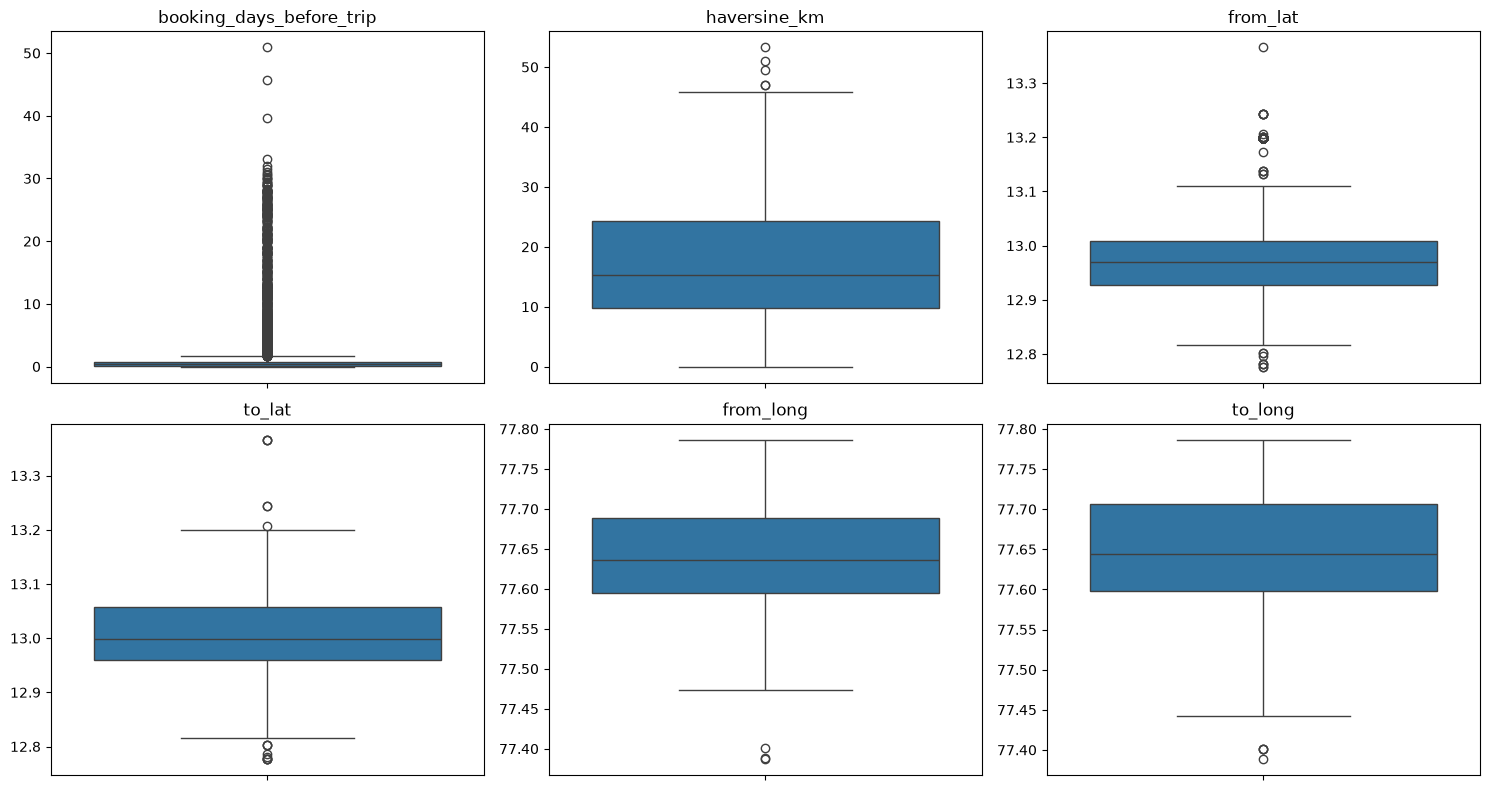

In [1606]:
#Sceen engineered/raw features for outliers
filled_train.columns
screen_columns = ['booking_days_before_trip','haversine_km','from_lat','to_lat','from_long','to_long']
n_cols = 3
n_rows = math.ceil(len(sceen_columns)/n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5* n_cols, 4* n_rows))
axes = axes.flatten()

for ax, col in zip(axes,screen_columns):
    sns.boxplot(y=filled_train[col], ax=ax)
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(screen_columns):]:
    ax.set_visible(False)

plt.tight_layout()

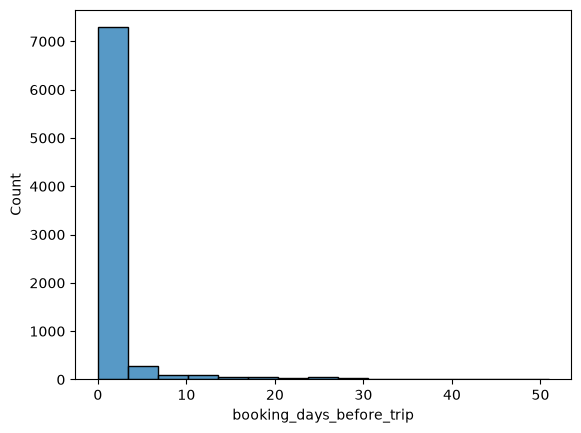

In [1607]:
sns.histplot(filled_train.booking_days_before_trip,bins=15)
plt.show()

#### Question 5: Feature Engineering
We used two engineered features, booking_days_before_trip and haversine_km. The justification for both is as follows.
booking_days_before_trip: The longer the time between booking and trip the higher the liklihood plans change for either party and a cancellation occurs.
haversine_km = this could go either way, for long trips the committment might raise the chance either party cancels, or extremely short trips maybe the consumer decided walking or biking would be a better method of transportation.
We screened for outlier values and while using the IQR method does result in some outliers we decided not to remove these as they represent realistic situations. Taxi rides booked out 50 days in advance, while rare are a service that is provided. Likewise, taxi rides of ~50km would be rare, but also in the realm of possibilities.

---

In [1608]:
corr = filled_train.corr().abs()  # drop .abs() if you want signed ranking

# Used AI to help find the most correlated variables as opposed to trying to view everything on a corr table
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

top_n = (upper.stack()
              .sort_values(ascending=False)
              .head(10))   # change 10 to your n
print(top_n)

package_id_missing   travel_type_id_3       1.000000
travel_type_id_2     travel_type_id_3       0.902279
package_id_missing   travel_type_id_2       0.902279
to_lat               haversine_km           0.559670
                     to_long                0.501942
vehicle_model_id_12  vehicle_model_id_89    0.405427
                     vehicle_model_id_85    0.403561
to_long              haversine_km           0.378234
vehicle_model_id_12  vehicle_model_id_65    0.354448
                     vehicle_model_id_28    0.332095
dtype: float64


In [1609]:
#Drop package_id missing as this basically says the same information as travel_type_id. 
#Drop to/from area as this should technically be categorical (codes tell nothing about real distance) and this information is captured within lat/long variables
#Do not remove haversine as distance doesn't capture all the same information ie; highway vs downtown travel differences
filled_train = filled_train.drop(columns=['package_id_missing','from_area_id','to_area_id'])
filled_train.columns

Index(['online_booking', 'mobile_site_booking', 'from_lat', 'from_long',
       'to_lat', 'to_long', 'to_date_missing', 'vehicle_model_id_10',
       'vehicle_model_id_12', 'vehicle_model_id_17', 'vehicle_model_id_23',
       'vehicle_model_id_24', 'vehicle_model_id_28', 'vehicle_model_id_30',
       'vehicle_model_id_36', 'vehicle_model_id_54', 'vehicle_model_id_64',
       'vehicle_model_id_65', 'vehicle_model_id_85', 'vehicle_model_id_86',
       'vehicle_model_id_87', 'vehicle_model_id_89', 'vehicle_model_id_90',
       'vehicle_model_id_91', 'travel_type_id_2', 'travel_type_id_3',
       'booking_days_before_trip', 'from_hour_1', 'from_hour_2', 'from_hour_3',
       'from_hour_4', 'from_hour_5', 'from_hour_6', 'from_hour_7',
       'from_hour_8', 'from_hour_9', 'from_hour_10', 'from_hour_11',
       'from_hour_12', 'from_hour_13', 'from_hour_14', 'from_hour_15',
       'from_hour_16', 'from_hour_17', 'from_hour_18', 'from_hour_19',
       'from_hour_20', 'from_hour_21', 'from_hour

In [1610]:
#unscale test set and perform same transformations
scaler = prep.named_steps['standardscaler']

filled_test = pd.DataFrame(scaler.inverse_transform(Z_test),
                            columns=X_test.columns, index=X_test.index)

filled_test = filled_test.drop(columns=['package_id_missing','from_area_id','to_area_id'])

#### Question 6: Check for redundancies
Anaylzed highly correlated predictors and used common knowledge to remove redundancies. Package_missing and travel type id are very highly correlated. Capture the same inforamtion here so removed. While area and lat/long were not correlated (area is a code) we still feel these carry duplicative information. We would have to transform area into categorical data anyway to decided to remove as we are still capturing this signal in Lat/Long data.

---

In [1615]:
folds = KFold(n_splits=10, shuffle=True, random_state=42)

for k in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(pipe, filled_train, y_train, cv=folds,
                             scoring='precision')
    print("k =", k, " CV recall: ", round(scores.mean(),ndigits=4))

k = 1  CV recall:  0.2359
k = 2  CV recall:  0.4132
k = 3  CV recall:  0.3691
k = 4  CV recall:  0.5087
k = 5  CV recall:  0.4653
k = 6  CV recall:  0.5775
k = 7  CV recall:  0.4746
k = 8  CV recall:  0.5215
k = 9  CV recall:  0.4879
k = 10  CV recall:  0.4223


#### Question 7: Evaluate K
We used a KNN 10 fold cross validation and decided to choose the mdoel that had the highest accuracy at about 92.6%. Slightly concerned in just picked no cancellation for everything though

In [1612]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=40))
knn.fit(filled_train, y_train)

knn_pred = knn.predict(filled_test)

print("KNN accuracy on the hidden data:", round(accuracy_score(y_test, knn_pred), 3))

KNN accuracy on the hidden data: 0.925


In [1613]:
print(confusion_matrix(y_test, knn_pred))

[[1849    0]
 [ 149    0]]


In [1614]:
simple = SimpleImputer(strategy='most_frequent')
simple.fit(y_train.values.reshape(-1, 1))

# A column of gaps, one per held-out bird, for the imputer to fill.
gaps = np.full((len(y_test), 1), np.nan, dtype=object)
simple_pred = simple.transform(gaps).ravel().astype(y_train.dtype)

print("SimpleImputer fills every gap with:", simple_pred[0])
print()
print("SimpleImputer accuracy:", round(accuracy_score(y_test, simple_pred), 3))
print("KNN accuracy:         ", round(accuracy_score(y_test, knn_pred), 3))

SimpleImputer fills every gap with: 0

SimpleImputer accuracy: 0.925
KNN accuracy:          0.925
